In [1]:
import warnings, os
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
from cycler import cycler
import holidays
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error
import lightgbm as lgb

os.makedirs("images", exist_ok=True)

In [2]:
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "axes.prop_cycle": cycler(color=["#1F3A5F", "#C8553D", "#5B8E7D"]),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#BBBBBB",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#E8E8E8",
    "grid.linewidth": 0.8,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlepad": 14,
    "axes.labelcolor": "#444444",
    "xtick.color": "#555555",
    "ytick.color": "#555555",
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
})

thousands = FuncFormatter(lambda x, _: f"{x/1000:,.0f}K")
SOURCE = "Source: Prasarana Malaysia, Ministry of Transport via data.gov.my"

In [3]:
URL = "https://storage.data.gov.my/transportation/ridership_headline.csv"
raw = pd.read_csv(URL, parse_dates=["date"])
print(raw.shape, raw["date"].min().date(), "to", raw["date"].max().date())

(2800, 15) 2019-01-01 to 2026-08-31


In [4]:
START = "2023-04-01"

ALL_LINES = {
    "rail_lrt_kj": "LRT Kelana Jaya Line",
    "rail_mrt_kajang": "MRT Kajang Line",
    "rail_mrt_pjy": "MRT Putrajaya Line",
    "rail_lrt_ampang": "LRT Ampang Line",
    "rail_monorail": "KL Monorail Line",
    "rail_lrt_shah_alam": "LRT Shah Alam Line",
}

COLORS = {
    "LRT Kelana Jaya Line": "#D62828",
    "MRT Kajang Line": "#2E8B57",
    "MRT Putrajaya Line": "#F2B705",
    "LRT Ampang Line": "#8B5E3C",
    "KL Monorail Line": "#8E6BBF",
    "LRT Shah Alam Line": "#2A6FBB",
}

df_all = (
    raw[raw["date"] >= START]
    .set_index("date")[list(ALL_LINES)]
    .asfreq("D")
    .rename(columns=ALL_LINES)
)

FOCUS = ["LRT Kelana Jaya Line", "MRT Kajang Line", "MRT Putrajaya Line"]
df = df_all[FOCUS].interpolate()

def colors_for(cols):
    return [COLORS[c] for c in cols]

print(df_all.isna().sum())
df.tail()

LRT Kelana Jaya Line       0
MRT Kajang Line            0
MRT Putrajaya Line         0
LRT Ampang Line            0
KL Monorail Line           0
LRT Shah Alam Line      1155
dtype: int64


,LRT Kelana Jaya Line,MRT Kajang Line,MRT Putrajaya Line
date,,,
2026-08-27,285779,293121,190601.0
2026-08-28,282980,297190,190485.0
2026-08-29,175979,223182,132258.0
2026-08-30,230076,274653,164920.0
2026-08-31,165188,214462,149695.0


,Set,Start,End,Days,Share (%)
0,Warm-up (lag history),2023-04-01,2024-03-29,364,29.1
1,Training,2024-03-30,2026-08-03,857,68.6
2,Testing,2026-08-04,2026-08-31,28,2.2
3,Total,2023-04-01,2026-08-31,1249,100.0


,First date,Last date,Days in window,Missing days,Avg daily trips
LRT Kelana Jaya Line,2023-04-01,2026-08-31,1249,0,232436.0
MRT Kajang Line,2023-04-01,2026-08-31,1249,0,234466.0
MRT Putrajaya Line,2023-04-01,2026-08-31,1249,0,135457.0
LRT Ampang Line,2023-04-01,2026-08-31,1249,0,177802.0
KL Monorail Line,2023-04-01,2026-08-31,1249,0,55209.0
LRT Shah Alam Line,2026-04-01,2026-08-31,1249,1155,34935.0


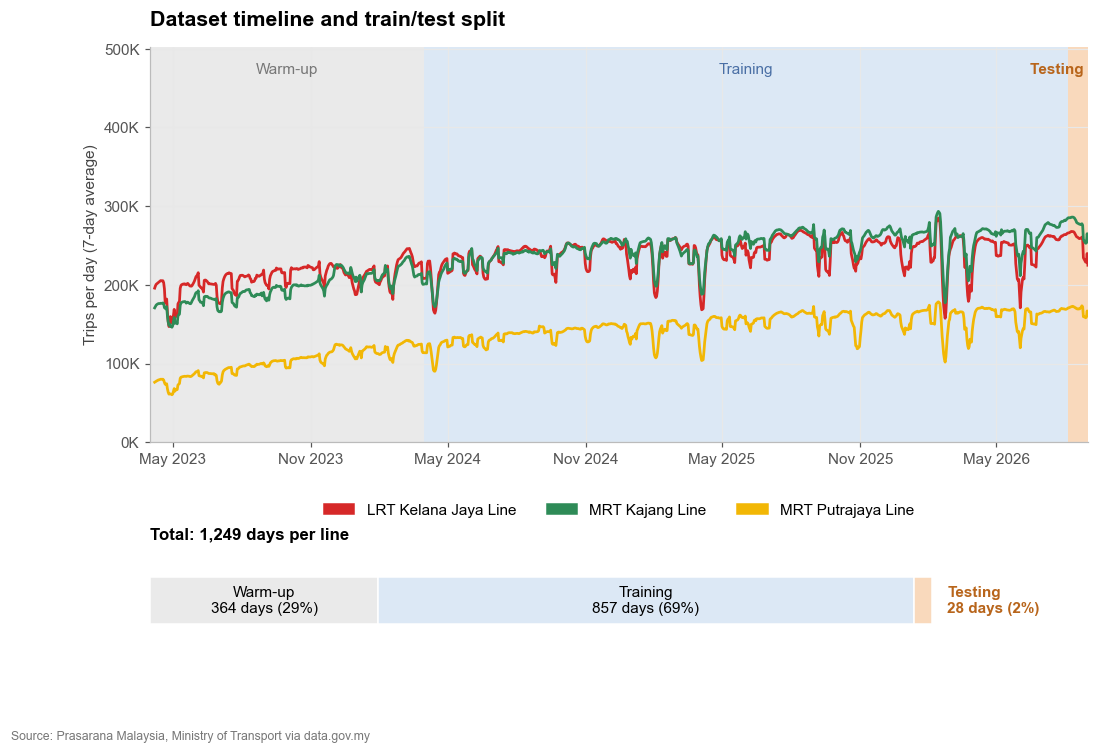

In [5]:
H = 28
MAX_LAG = 364

n_total = len(df)
n_warmup = MAX_LAG
n_test = H
n_train = n_total - n_warmup - n_test

t_start = df.index[0]
t_train = df.index[MAX_LAG]
t_test = df.index[-H]
t_end = df.index[-1]

split = pd.DataFrame({
    "Set": ["Warm-up (lag history)", "Training", "Testing", "Total"],
    "Start": [t_start.date(), t_train.date(), t_test.date(), t_start.date()],
    "End": [(t_train - pd.Timedelta(days=1)).date(),
            (t_test - pd.Timedelta(days=1)).date(), t_end.date(), t_end.date()],
    "Days": [n_warmup, n_train, n_test, n_total],
})
split["Share (%)"] = (split["Days"] / n_total * 100).round(1)
split.to_csv("dataset_split.csv", index=False)
display(split)

quality = pd.DataFrame({
    "First date": df_all.apply(lambda s: s.first_valid_index().date()),
    "Last date": df_all.apply(lambda s: s.last_valid_index().date()),
    "Days in window": len(df_all),
    "Missing days": df_all.isna().sum(),
    "Avg daily trips": df_all.mean().round(0),
})
display(quality)

SPLIT_COLORS = {"Warm-up": "#EAEAEA", "Training": "#DCE8F5", "Testing": "#F9D9BC"}
EDGES = {"Warm-up": (t_start, t_train),
         "Training": (t_train, t_test),
         "Testing": (t_test, t_end)}
COUNTS = {"Warm-up": n_warmup, "Training": n_train, "Testing": n_test}

fig, (ax, ax2) = plt.subplots(
    2, 1, figsize=(11, 7),
    gridspec_kw={"height_ratios": [5, 1], "hspace": 0.5},
)

smooth = df.rolling(7).mean()
for name, (a, b) in EDGES.items():
    ax.axvspan(a, b, color=SPLIT_COLORS[name], lw=0, zorder=0)
for line in FOCUS:
    ax.plot(smooth.index, smooth[line], color=COLORS[line], lw=1.8, zorder=2)

trans = ax.get_xaxis_transform()
ax.text(t_start + (t_train - t_start) / 2, 0.96, "Warm-up", transform=trans,
        ha="center", va="top", fontsize=10, color="#777777")
ax.text(t_train + (t_test - t_train) / 2, 0.96, "Training", transform=trans,
        ha="center", va="top", fontsize=10, color="#4A6FA5")
ax.text(t_end, 0.96, "Testing ", transform=trans,
        ha="right", va="top", fontsize=10, color="#B8651B", fontweight="bold")

ax.set_ylim(0, df.max().max() * 1.25)
ax.set_xlim(t_start, t_end)
ax.set_title("Dataset timeline and train/test split")
ax.set_ylabel("Trips per day (7-day average)")
ax.yaxis.set_major_formatter(thousands)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(handles=[Patch(color=COLORS[l], label=l) for l in FOCUS],
          loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)

left = 0
for name in ["Warm-up", "Training", "Testing"]:
    n = COUNTS[name]
    ax2.barh(0, n, left=left, color=SPLIT_COLORS[name], edgecolor="white", height=0.6)
    if name != "Testing":
        ax2.text(left + n / 2, 0, f"{name}\n{n:,} days ({n / n_total:.0%})",
                 ha="center", va="center", fontsize=10)
    left += n
ax2.text(n_total * 1.02, 0, f"Testing\n{n_test} days ({n_test / n_total:.0%})",
         ha="left", va="center", fontsize=10, color="#B8651B", fontweight="bold")
ax2.set_xlim(0, n_total * 1.2)
ax2.set_ylim(-0.5, 0.5)
ax2.axis("off")
ax2.set_title(f"Total: {n_total:,} days per line", fontsize=11, loc="left")

fig.text(0.01, -0.02, SOURCE, fontsize=8, color="#777777")
plt.savefig("images/00_dataset_split.png")
plt.show()

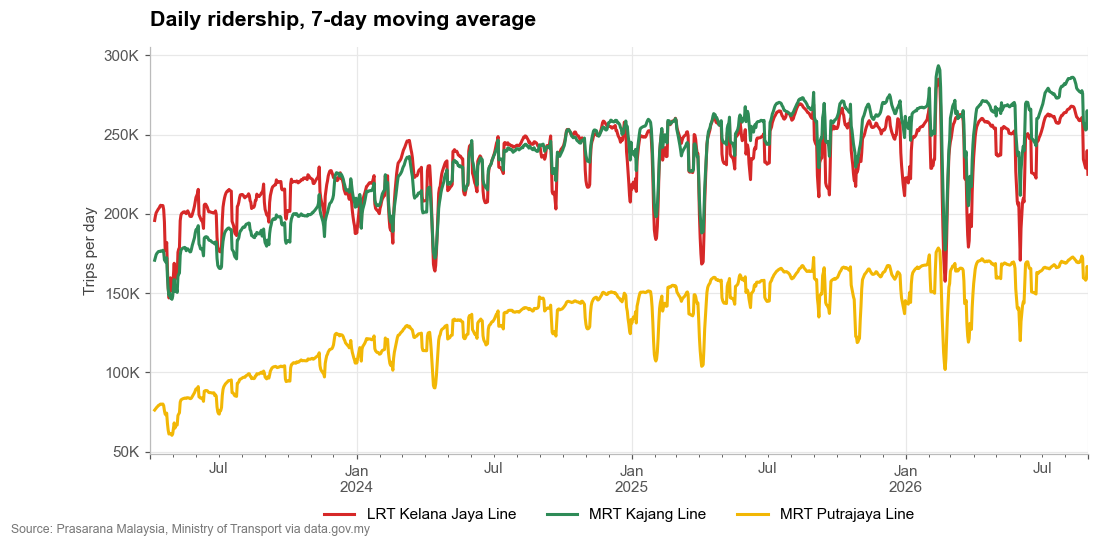

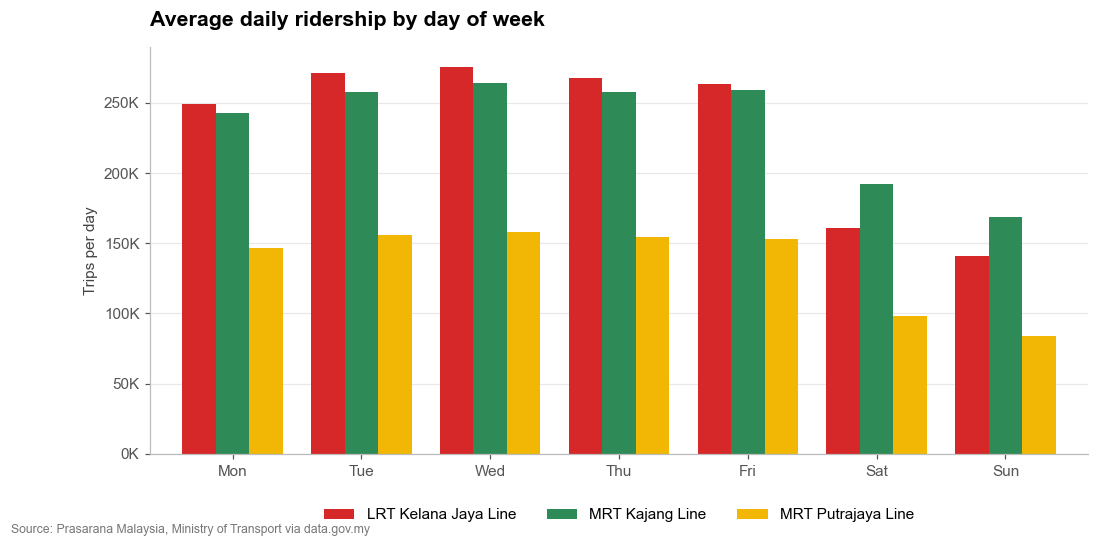

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.8))
df.rolling(7).mean().plot(ax=ax, color=colors_for(df.columns), linewidth=2)
ax.set_title("Daily ridership, 7-day moving average")
ax.set_xlabel("")
ax.set_ylabel("Trips per day")
ax.yaxis.set_major_formatter(thousands)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
fig.text(0.01, -0.04, SOURCE, fontsize=8, color="#777777")
plt.savefig("images/01_trend.png")
plt.show()

dow = df.groupby(df.index.dayofweek).mean()
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(11, 4.8))
dow.plot(kind="bar", ax=ax, width=0.78, color=colors_for(dow.columns))
ax.set_title("Average daily ridership by day of week")
ax.set_xlabel("")
ax.set_ylabel("Trips per day")
ax.yaxis.set_major_formatter(thousands)
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
fig.text(0.01, -0.04, SOURCE, fontsize=8, color="#777777")
plt.savefig("images/02_weekday.png")
plt.show()

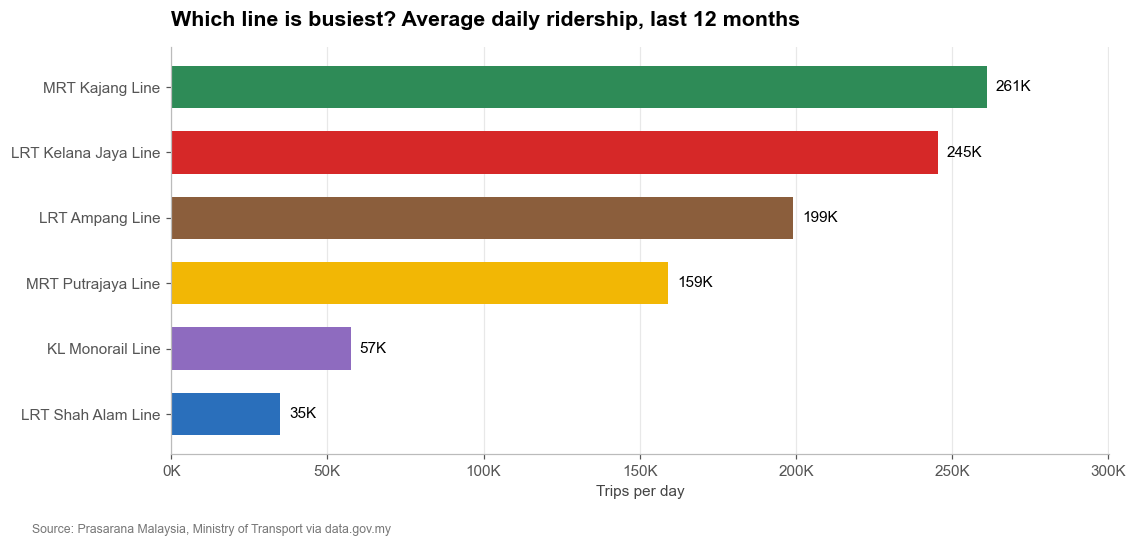

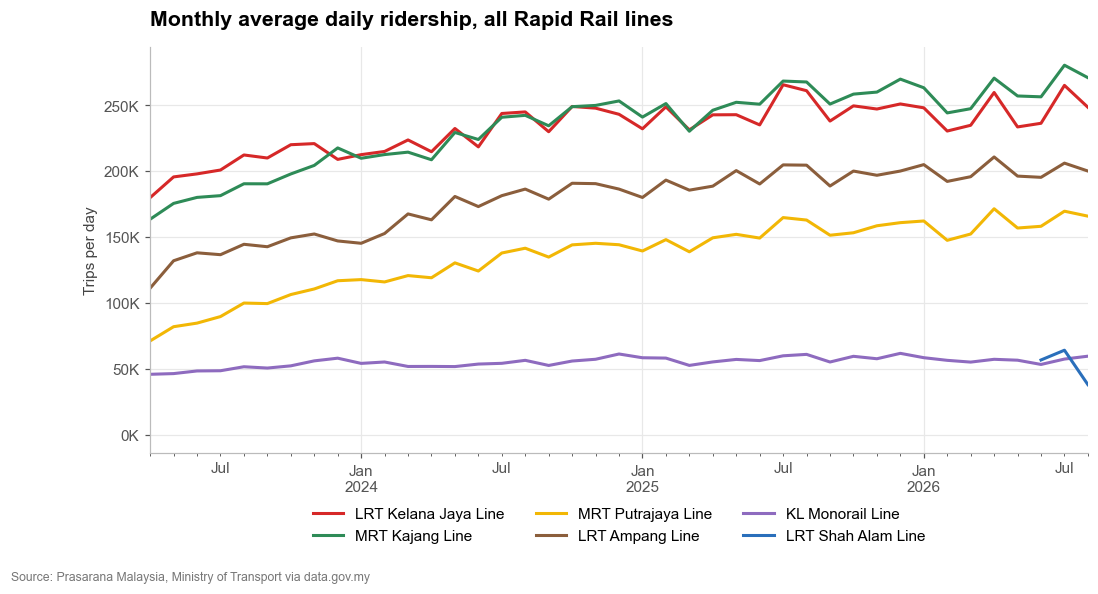

,Avg daily trips,Peak day trips,Peak date
MRT Kajang Line,261043.0,401756.0,2025-12-31
LRT Kelana Jaya Line,245405.0,352504.0,2025-12-31
LRT Ampang Line,199099.0,258283.0,2025-12-31
MRT Putrajaya Line,159179.0,236225.0,2025-12-31
KL Monorail Line,57444.0,99361.0,2025-12-31
LRT Shah Alam Line,34935.0,110341.0,2026-07-04


In [7]:
end = df_all.index.max()
last12 = df_all.loc[end - pd.Timedelta(days=364):]

avg = last12.mean().sort_values()
fig, ax = plt.subplots(figsize=(11, 4.8))
bars = ax.barh(avg.index, avg.values, color=[COLORS[i] for i in avg.index], height=0.65)
ax.bar_label(bars, labels=[f"{v/1000:,.0f}K" for v in avg.values], padding=6, fontsize=10)
ax.set_title("Which line is busiest? Average daily ridership, last 12 months")
ax.xaxis.set_major_formatter(thousands)
ax.set_xlabel("Trips per day")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, avg.max() * 1.15)
fig.text(0.01, -0.04, SOURCE, fontsize=8, color="#777777")
plt.savefig("images/03_busiest_lines.png")
plt.show()

monthly = df_all.resample("MS").mean()
fig, ax = plt.subplots(figsize=(11, 4.8))
monthly.plot(ax=ax, color=colors_for(monthly.columns), linewidth=2)
ax.set_title("Monthly average daily ridership, all Rapid Rail lines")
ax.set_xlabel("")
ax.set_ylabel("Trips per day")
ax.yaxis.set_major_formatter(thousands)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
fig.text(0.01, -0.13, SOURCE, fontsize=8, color="#777777")
plt.savefig("images/04_monthly_all_lines.png")
plt.show()

summary = pd.DataFrame({
    "Avg daily trips": last12.mean().round(0),
    "Peak day trips": last12.max(),
    "Peak date": last12.idxmax().dt.date,
}).sort_values("Avg daily trips", ascending=False)
summary

In [8]:
my_hol = holidays.Malaysia(years=range(2023, 2027))
MODELS = ["Seasonal Naive", "Holt-Winters", "LightGBM"]

FEATURE_LABELS = {
    "day_of_week": "Day of week",
    "month": "Month",
    "day_of_month": "Day of month",
    "is_holiday": "Public holiday",
    "lag_28": "Ridership 28 days ago",
    "lag_35": "Ridership 35 days ago",
    "lag_364": "Ridership 1 year ago",
    "roll_mean_28": "28-day average",
}

def build_features(series):
    d = pd.DataFrame({"y": series})
    d["day_of_week"] = d.index.dayofweek
    d["month"] = d.index.month
    d["day_of_month"] = d.index.day
    d["is_holiday"] = [int(x in my_hol) for x in d.index]
    d["lag_28"] = series.shift(28)
    d["lag_35"] = series.shift(35)
    d["lag_364"] = series.shift(364)
    d["roll_mean_28"] = series.shift(28).rolling(28).mean()
    return d.dropna()

def evaluate(actual, pred):
    return {
        "MAE": mean_absolute_error(actual, pred),
        "RMSE": mean_squared_error(actual, pred) ** 0.5,
        "MAPE (%)": (np.abs((actual - pred) / actual)).mean() * 100,
    }

results, forecasts, importances = [], {}, {}

for line in FOCUS:
    series = df[line]
    d = build_features(series)
    train, test = d.iloc[:-H], d.iloc[-H:]
    features = [c for c in d.columns if c != "y"]
    train_series = series.iloc[:-H]

    pred_naive = np.tile(train_series.iloc[-7:].values, H // 7)

    hw = ExponentialSmoothing(train_series, trend="add", damped_trend=True,
                              seasonal="add", seasonal_periods=7).fit()
    pred_hw = hw.forecast(H).values

    model = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05,
                              num_leaves=15, random_state=42, verbose=-1)
    model.fit(train[features], train["y"])
    pred_lgb = model.predict(test[features])

    forecasts[line] = pd.DataFrame({
        "Actual": test["y"],
        "Seasonal Naive": pred_naive,
        "Holt-Winters": pred_hw,
        "LightGBM": pred_lgb,
    }, index=test.index)

    importances[line] = pd.Series(model.feature_importances_,
                                  index=[FEATURE_LABELS[f] for f in features])

    for name in MODELS:
        results.append({"Line": line, "Model": name,
                        **evaluate(test["y"].values, forecasts[line][name].values)})

res = pd.DataFrame(results).round(1)
res.to_csv("results.csv", index=False)
res

C:\Users\aweks\anaconda3\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
  File "C:\Users\aweks\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\aweks\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\aweks\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^

,Line,Model,MAE,RMSE,MAPE (%)
0,LRT Kelana Jaya Line,Seasonal Naive,19690.8,42926.9,10.6
1,LRT Kelana Jaya Line,Holt-Winters,19661.7,41436.4,10.8
2,LRT Kelana Jaya Line,LightGBM,10629.7,16066.3,4.6
3,MRT Kajang Line,Seasonal Naive,17445.8,33537.3,7.5
4,MRT Kajang Line,Holt-Winters,16668.8,32888.4,7.3
5,MRT Kajang Line,LightGBM,12021.5,17518.2,4.5
6,MRT Putrajaya Line,Seasonal Naive,10285.8,21957.3,7.4
7,MRT Putrajaya Line,Holt-Winters,10347.8,21209.9,7.3
8,MRT Putrajaya Line,LightGBM,7805.2,13007.6,5.1


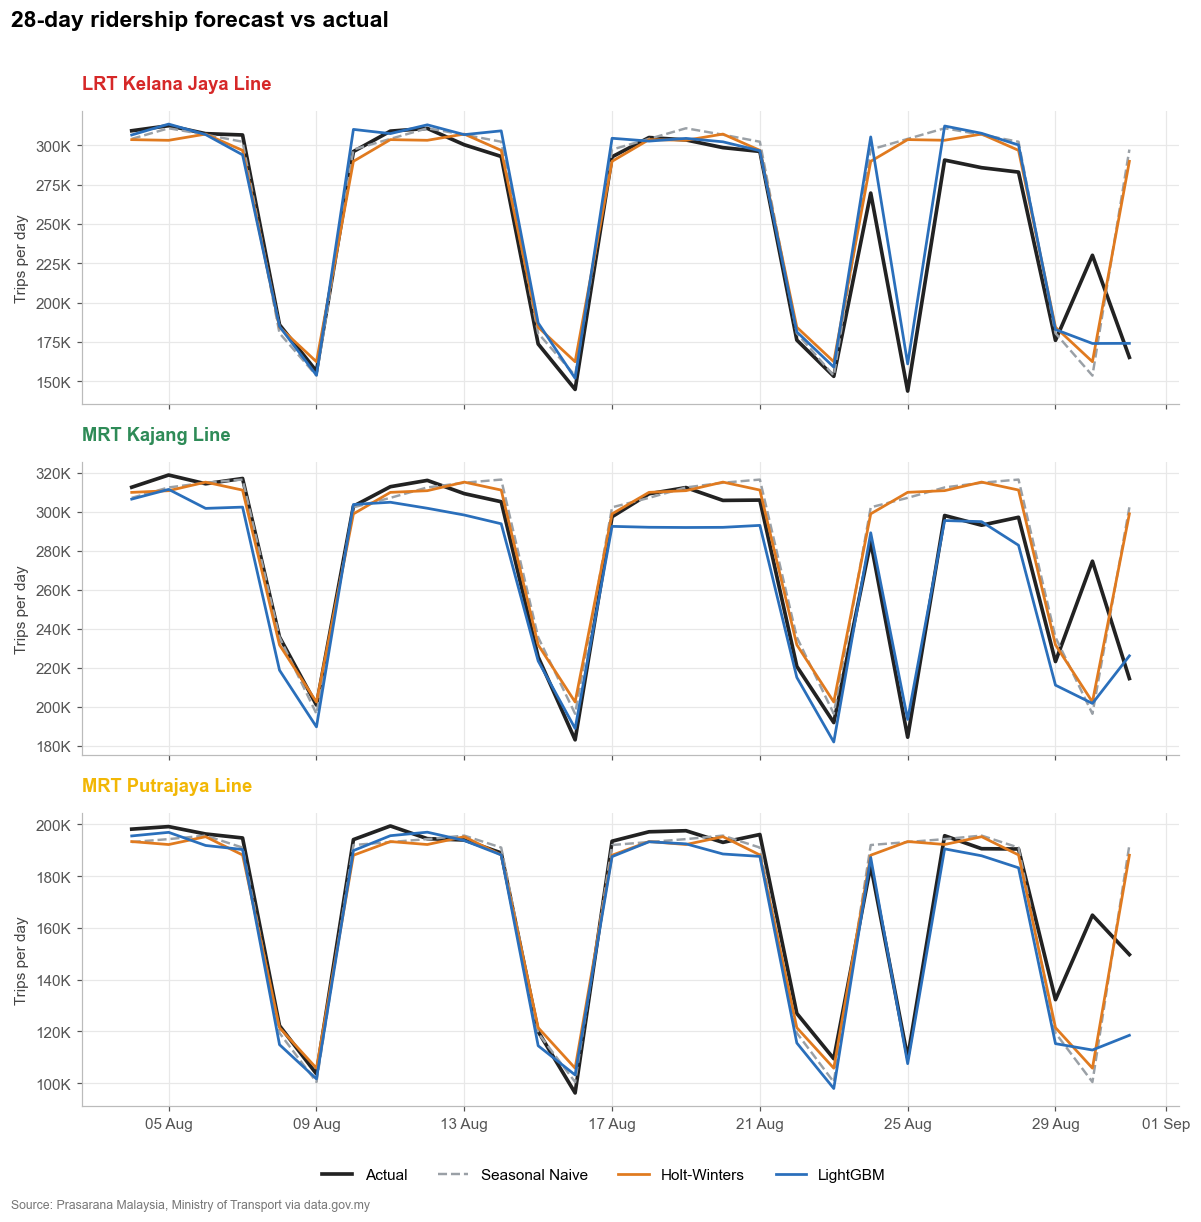

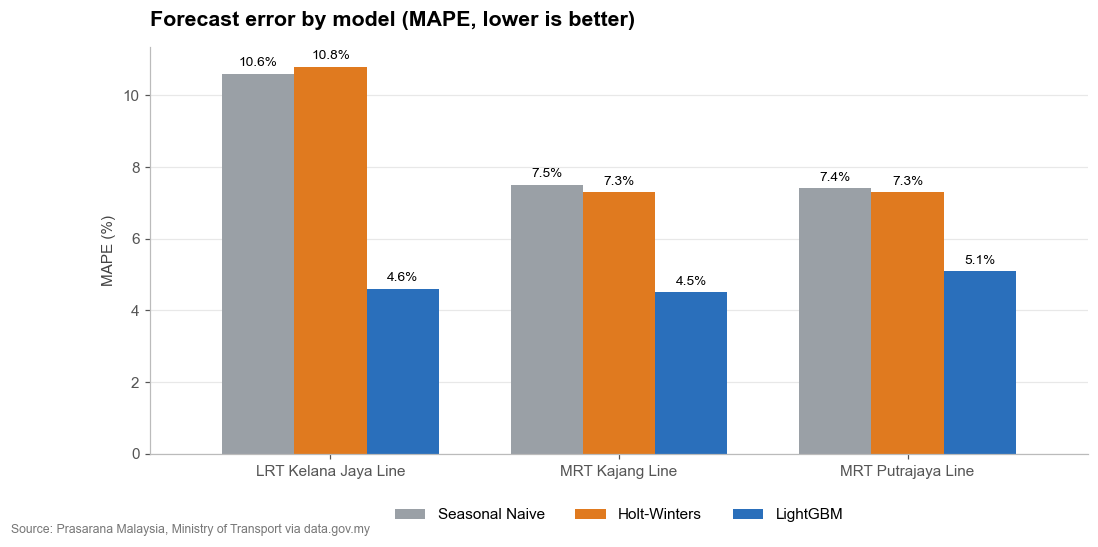

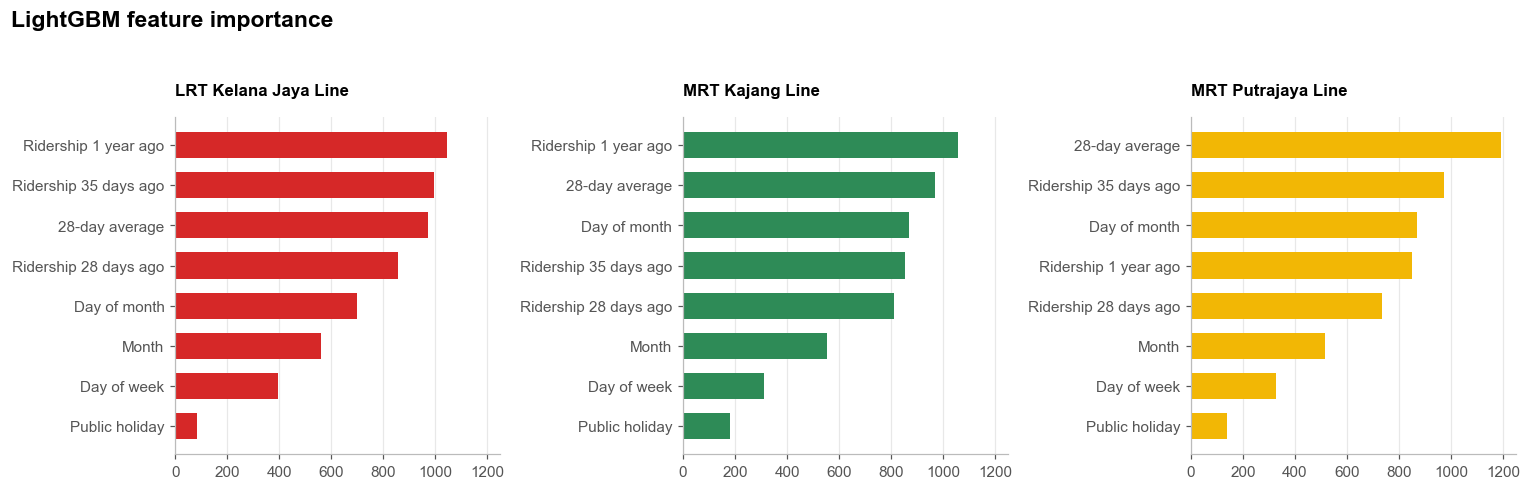

In [9]:
MODEL_STYLE = {
    "Actual":         dict(color="#222222", lw=2.4),
    "Seasonal Naive": dict(color="#9AA0A6", lw=1.6, ls="--"),
    "Holt-Winters":   dict(color="#E07A1F", lw=1.8),
    "LightGBM":       dict(color="#2A6FBB", lw=1.8),
}

fig, axes = plt.subplots(3, 1, figsize=(11, 11), sharex=True)
for ax, line in zip(axes, FOCUS):
    f = forecasts[line]
    for name, style in MODEL_STYLE.items():
        ax.plot(f.index, f[name], label=name, **style)
    ax.set_title(line, fontsize=12, color=COLORS[line])
    ax.set_ylabel("Trips per day")
    ax.yaxis.set_major_formatter(thousands)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False,
           bbox_to_anchor=(0.5, 0.0))
fig.suptitle("28-day ridership forecast vs actual", x=0.01, ha="left",
             fontsize=15, fontweight="bold")
fig.text(0.01, -0.01, SOURCE, fontsize=8, color="#777777")
plt.tight_layout(rect=[0, 0.04, 1, 0.97])
plt.savefig("images/05_actual_vs_forecast.png")
plt.show()

piv = res.pivot(index="Line", columns="Model", values="MAPE (%)")[MODELS]
piv = piv.loc[FOCUS]
fig, ax = plt.subplots(figsize=(11, 4.8))
piv.plot(kind="bar", ax=ax, width=0.75,
         color=[MODEL_STYLE[m]["color"] for m in MODELS])
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", fontsize=9, padding=3)
ax.set_title("Forecast error by model (MAPE, lower is better)")
ax.set_xlabel("")
ax.set_ylabel("MAPE (%)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
fig.text(0.01, -0.04, SOURCE, fontsize=8, color="#777777")
plt.savefig("images/06_error_comparison.png")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharex=True)
for ax, line in zip(axes, FOCUS):
    imp = importances[line].sort_values()
    ax.barh(imp.index, imp.values, color=COLORS[line], height=0.65)
    ax.set_title(line, fontsize=11)
    ax.grid(axis="y", visible=False)
fig.suptitle("LightGBM feature importance", x=0.01, ha="left",
             fontsize=15, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig("images/07_feature_importance.png")
plt.show()